# Entrenamiento y diagnóstico de Modelo

Este notebook realiza la normalización de las imágenes, el entrenamiento y evaluación del modelo.

El proceso de este notebook es el siguiente:
1. Montar Google Drive el cual almacena los subsets (Train, Val, Test).
2. Se define la arquitectura de la CNN.
3. Realiza el entrenamiento y se visualiza el error y accuracy por epoch.
4. Se guardan los pesos de la época con mejor entrenamiento respecto al loss de validación

En este caso, se debe ajustar la ruta a donde está almacenado la información del dataset. Dentro de el existen carpetas de glioma, meningiona, pituitario y sano.

Tras correr el código, se obtienen archivos que contienen los pesos congelados, la arquitectura y el orden de clases.

### Librerías

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
PROJECT_DIR = Path("/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto")
CLASS_ORDER = ["glioma", "meningioma", "pituitary", "healthy"]
MODEL_DIR = PROJECT_DIR / "models"

SPLIT_DIR = PROJECT_DIR / "dataset_split"

TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR   = SPLIT_DIR / "val"
TEST_DIR  = SPLIT_DIR / "test"

# Comprobar que existan las tres carpetas
required_dirs = [TRAIN_DIR, VAL_DIR, TEST_DIR]
missing_dirs = [folder for folder in required_dirs if not folder.exists()]

if missing_dirs:
    raise FileNotFoundError(
        "No se encontraron todas las carpetas del split: "
        + ", ".join(str(folder) for folder in missing_dirs)
    )

# Contar imágenes por categoría sin abrirlas
extensions = {".jpg", ".jpeg", ".png"}

def conteo_imagenes(folder):
    return {
        nombre_clase: sum(
            1 for file in (folder / nombre_clase).rglob("*")
            if file.is_file() and file.suffix.lower() in extensions
        )
        for nombre_clase in CLASS_ORDER
    }

conteo_subsets = pd.DataFrame({
    "train": conteo_imagenes(TRAIN_DIR),
    "val": conteo_imagenes(VAL_DIR),
    "test": conteo_imagenes(TEST_DIR)
})

display(conteo_subsets)
print("Total de imágenes:", int(conteo_subsets.sum().sum()))

,train,val,test
glioma,3003,188,563
meningioma,1874,117,352
pituitary,2165,135,406
healthy,1406,88,263


Total de imágenes: 10560


## Crear datasets de TensorFlow desde las carpetas

`image_dataset_from_directory` lee directamente la estructura de la ruta, se definen los mismos parámetros para cada subset.

In [20]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_ORDER,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "val",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_ORDER,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_ORDER,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Orden de clases:", train_ds.class_names)

# Normalización a [0,1] y optimización de lectura.
normalization = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 8448 files belonging to 4 classes.
Found 528 files belonging to 4 classes.
Found 1584 files belonging to 4 classes.
Orden de clases: ['glioma', 'meningioma', 'pituitary', 'healthy']


### Visualizar un batch preprocesado

Forma de imágenes: (32, 128, 128, 3)
Rango de píxeles: 0.0 a 1.0


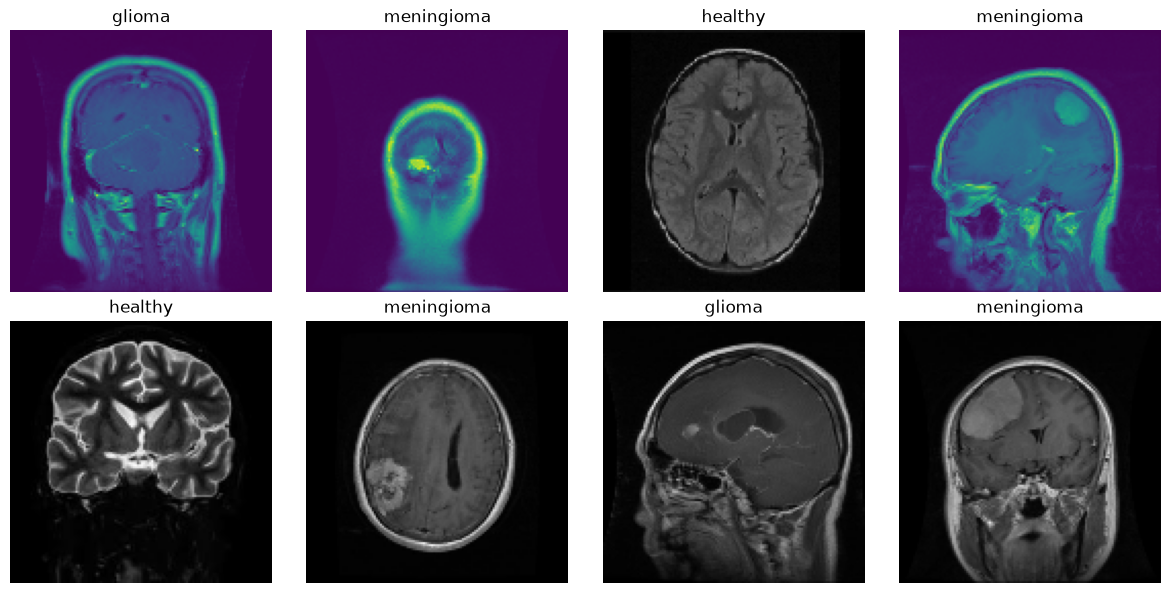

In [21]:
images, labels = next(iter(train_ds))
print("Forma de imágenes:", images.shape)
print("Rango de píxeles:", float(tf.reduce_min(images)), "a", float(tf.reduce_max(images)))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy())
    ax.set_title(CLASS_ORDER[int(labels[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Construcción de CNN

Este es el modelo de referencia (*baseline*), no el modelo definitivo. La red aprende características mediante convoluciones y reduce la dimensión con MaxPooling.

In [22]:
NUM_CLASSES = len(CLASS_ORDER)

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03),
], name="data_augmentation")

def build_baseline_cnn(input_shape=(128, 128, 3), num_classes=4):
    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="brain_tumor_baseline_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_baseline_cnn(num_classes=NUM_CLASSES)
model.summary()

Model: "brain_tumor_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento de CNN

In [23]:
EPOCHS = 20

best_model_path = MODEL_DIR / "brain_tumor_baseline_best.keras"

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20


/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/entorno/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


264/264 ━━━━━━━━━━━━━━━━━━━━ 364s 1s/step - accuracy: 0.4996 - loss: 1.1173 - val_accuracy: 0.3731 - val_loss: 1.8245 - learning_rate: 0.0010
Epoch 2/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 326s 1s/step - accuracy: 0.6444 - loss: 0.8666 - val_accuracy: 0.3807 - val_loss: 1.9585 - learning_rate: 0.0010
Epoch 3/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 319s 1s/step - accuracy: 0.6785 - loss: 0.7770 - val_accuracy: 0.6061 - val_loss: 0.9193 - learning_rate: 0.0010
Epoch 4/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 317s 1s/step - accuracy: 0.7090 - loss: 0.7042 - val_accuracy: 0.6155 - val_loss: 0.8570 - learning_rate: 0.0010
Epoch 5/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 341s 1s/step - accuracy: 0.7267 - loss: 0.6525 - val_accuracy: 0.4962 - val_loss: 1.3543 - learning_rate: 0.0010
Epoch 6/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 381s 1s/step - accuracy: 0.7411 - loss: 0.6075 - val_accuracy: 0.5114 - val_loss: 1.3382 - learning_rate: 0.0010
Epoch 7/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 320s 1s/step - accuracy: 0.7605 - loss: 0.5599 - val_

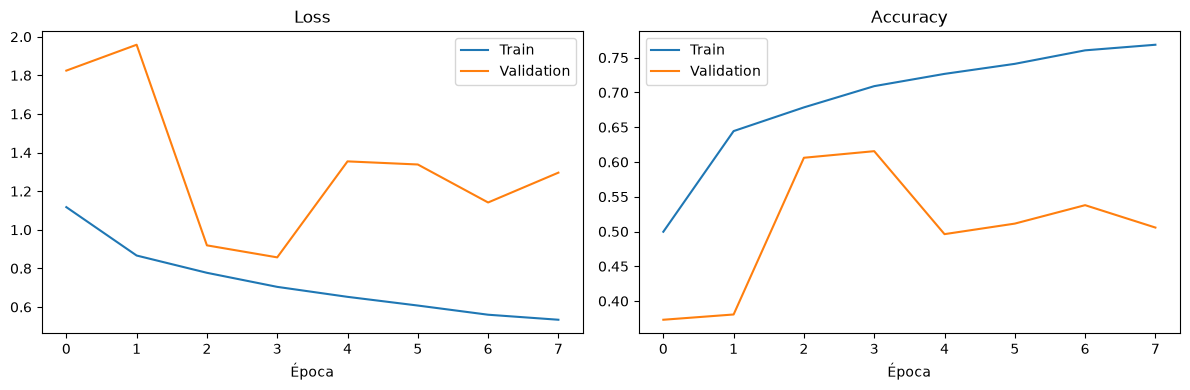

In [24]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["loss"], label="Train")
axes[0].plot(history_df["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history_df["accuracy"], label="Train")
axes[1].plot(history_df["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Época")
axes[1].legend()
plt.tight_layout()
plt.show()

## Evaluar una sola vez en Test

50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 366ms/step - accuracy: 0.6263 - loss: 0.8367
Test loss: 0.8367
Test accuracy: 0.6263


2026-11-04 15:11:34.628013: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 329ms/step
              precision    recall  f1-score   support

      glioma       0.79      0.58      0.67       563
  meningioma       0.52      0.40      0.45       352
   pituitary       0.75      0.66      0.70       406
     healthy       0.48      0.98      0.64       263

    accuracy                           0.63      1584
   macro avg       0.63      0.65      0.62      1584
weighted avg       0.67      0.63      0.62      1584



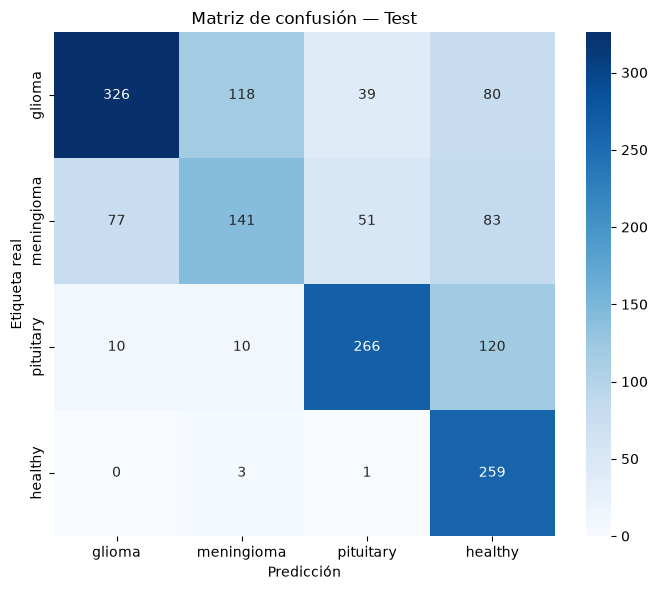

In [ ]:
# Se carga el mejor checkpoint guardado según el loss de validación
model = keras.models.load_model(best_model_path)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_ORDER,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER
)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión — Test")
plt.tight_layout()
plt.show()

## Guardar el modelo completo, los pesos y las clases

Se almacenan los siguientes archivos:
- **brain_tumor_baseline.keras**: modelo completo (arquitectura + pesos + configuración).
- **brain_tumor_weights.weights.h5**: solo los pesos para poder cargarlos en una arquitectura recreada igual.
- **class_names.json**: orden de clases necesario para interpretar las salidas.

In [26]:
# Modelo completo
full_model_path = MODEL_DIR / "brain_tumor_baseline.keras"
model.save(full_model_path)

# Pesos solamente
weights_path = MODEL_DIR / "brain_tumor_weights.weights.h5"
model.save_weights(weights_path)

# Etiquetas/orden de salida
class_names_path = MODEL_DIR / "class_names.json"
with open(class_names_path, "w", encoding="utf-8") as f:
    json.dump(CLASS_ORDER, f, ensure_ascii=False, indent=2)

print("Archivos guardados:")
for p in [full_model_path, weights_path, class_names_path]:
    print(p, "—", f"{p.stat().st_size / (1024**2):.2f} MB")

Archivos guardados:
/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/models/brain_tumor_baseline.keras — 4.89 MB
/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/models/brain_tumor_weights.weights.h5 — 4.88 MB
/Users/sebaschitiva/Desktop/Concentración_IA_Avanzada/Periodo_Avanzado/Proyecto/models/class_names.json — 0.00 MB
